# NicheJEPA Tutorial xhs1000-skin

- Creator: Sebastian Birk (sb75@sanger.ac.uk) Mohammad Vali Sanian (mohammad.sanian@helsinki.fi)
- Date of Creation: 30.06.2025
- Date of Last Modification: 08.07.2025 (by Mohammad Vali Sanian mohammad.sanian@helsinki.fi)

## 1. Setup

### 1.1 Load Libraries 

In [40]:
%load_ext autoreload
%autoreload 2

In [1]:
import sys
sys.path.append("../../utils")

In [236]:
import logging
import os
import warnings
from typing import List, Tuple
import torch
from sklearn.metrics import silhouette_score
import gseapy as gp
from sklearn.metrics.pairwise import cosine_similarity
import json
import pickle
import numpy as np
import pandas as pd
import anndata as ad
import pandas as pd
import scanpy as sc
import scib_metrics
from datasets import load_from_disk
from matplotlib.colors import Normalize
import squidpy as sq
from tqdm import tqdm
from app.infer import (embed_dataset,
                       harmonize_adata,
                       tokenize_adata,
                       perturb_dataset,
                       harmonize_tokenize_embed_pipeline,
                       get_gene_embed,
                       get_average_gene_embed,
                       get_spatial_score,
                       get_emd_distance )
from nichejepa.utils.evaluation import (get_top_gene_score,
                                        get_top_gene_pairs
                                        )
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score

from analysis_utils import *
from benchmarking_utils import max_overlap_plot

In [3]:
## This function takes a list of cell_ids and returns the corresponding dataset object.
def subset_by_cell_ids(dataset, cell_id_list):
    cell_id_set = set(cell_id_list)
    cell_ids = dataset['cell_id']
    indices = [i for i, cid in tqdm(enumerate(cell_ids), total=len(cell_ids), desc="Finding matching indices") if cid in cell_id_set]
    return dataset.select(indices)


In [6]:
import os

import anndata as ad
import omnipath as op
import pandas as pd
from cellphonedb.utils import db_releases_utils, db_utils
from IPython.display import HTML, display


def get_adata_cellphonedb_lr_pairs(
        adata: ad.AnnData,
        save_folder_path: str,
        cpdb_version: str = 'v5.0.0',
        ) -> pd.DataFrame:
    """
    Retrieve ligand-receptor pairs from CellPhoneDB
    (https://www.cellphonedb.org/) that are present in an AnnData object.

    Parameters
    -----------
    adata:
        The AnnData object to check for gene availability
    save_folder_path

    Returns
    -----------
    lr_interaction_df:
        A DataFrame containing ligand and receptor pairs present in the
        AnnData object.
    """
    # Display CellPhoneDB version
    display(HTML(db_releases_utils.get_remote_database_versions_html()[
        'db_releases_html_table']))

    # Path where the input files to generate the database are/will be located
    os.makedirs(save_folder_path, exist_ok=True)
    cpdb_target_dir = os.path.join(save_folder_path, cpdb_version)

    # Download the CellPhoneDB database
    db_utils.download_database(cpdb_target_dir, cpdb_version)

    # Retrieve CellPhoneDB interactions
    intercell_df = pd.read_csv(f'{cpdb_target_dir}/interaction_input.csv')

    # Filter for lr interactions
    lr_interaction_df = intercell_df[
        intercell_df['directionality'] == 'Ligand-Receptor']

    # Remove interactions involving protein complexes
    lr_interaction_df = lr_interaction_df[
        ~lr_interaction_df['interactors'].apply(lambda x: '+' in x)]

    # Only keep ligand and receptor gene names
    lr_interaction_df['ligand'] = lr_interaction_df[
        'interactors'].apply(lambda x: x.split('-')[0])
    lr_interaction_df['receptor'] = lr_interaction_df[
        'interactors'].apply(lambda x: x.split('-')[1])
    lr_interaction_df = lr_interaction_df[['ligand', 'receptor']]

    # Map gene names to ensembl IDs, keeping only genes present in the AnnData
    # object
    lr_interaction_df['ligand'] = lr_interaction_df[
        'ligand'].map(adata.var['ensembl_id'])
    lr_interaction_df['receptor'] = lr_interaction_df[
        'receptor'].map(adata.var['ensembl_id'])

    print()

    # Drop interactions where ligand or receptor is not in the AnnData object
    lr_interaction_df = lr_interaction_df.dropna()

    return lr_interaction_df


def get_adata_omnipath_lr_pairs(
        adata: ad.AnnData,
        min_curation_effort: int = 2
        ) -> pd.DataFrame:
    """
    Retrieve ligand-receptor pairs from OmniPath (https://omnipathdb.org/) that
    are present in an AnnData object.

    Parameters
    -----------
    adata:
        The AnnData object to check for gene availability
    min_curation_effort:
        Minimum curation effort parameter of the OmniPath database.

    Returns
    -----------
    lr_interaction_df:
        A DataFrame containing ligand and receptor pairs present in the
        AnnData object.
    """
    # Retrieve OmniPath interactions
    intercell_df = op.interactions.import_intercell_network(
        include=['omnipath', 'pathwayextra', 'ligrecextra'])

    # Filter for lr interactions
    lr_interaction_df = intercell_df[
        (intercell_df['category_intercell_source'] == 'ligand') &
        (intercell_df['category_intercell_target'] == 'receptor')]

    # Filter for minimum curation effort
    lr_interaction_df = lr_interaction_df[
        lr_interaction_df['curation_effort'] >= min_curation_effort]

    # Remove interactions involving protein complexes
    lr_interaction_df = lr_interaction_df[
        ~lr_interaction_df['genesymbol_intercell_source'].apply(
            lambda x: 'COMPLEX' in x)]
    lr_interaction_df = lr_interaction_df[
        ~lr_interaction_df['genesymbol_intercell_target'].apply(
            lambda x: 'COMPLEX' in x)]

    # Only keep ligand and receptor gene names
    lr_interaction_df = lr_interaction_df[
        ['genesymbol_intercell_source', 'genesymbol_intercell_target']]

    # Map gene names to ensembl IDs, keeping only genes present in the AnnData
    # object
    lr_interaction_df['ligand'] = lr_interaction_df[
        'genesymbol_intercell_source'].map(adata.var['ensembl_id'])
    lr_interaction_df['receptor'] = lr_interaction_df[
        'genesymbol_intercell_target'].map(adata.var['ensembl_id'])
    lr_interaction_df.drop(
        ['genesymbol_intercell_source', 'genesymbol_intercell_target'],
        axis=1,
        inplace=True)

    # Drop interactions where ligand or receptor is not in the AnnData object
    lr_interaction_df = lr_interaction_df.dropna()

    return lr_interaction_df

INFO:root:Downloading data from `https://omnipathdb.org/queries/enzsub?format=json`
INFO:root:Downloading data from `https://omnipathdb.org/queries/interactions?format=json`
INFO:root:Downloading data from `https://omnipathdb.org/queries/complexes?format=json`
INFO:root:Downloading data from `https://omnipathdb.org/queries/annotations?format=json`
INFO:root:Downloading data from `https://omnipathdb.org/queries/intercell?format=json`
INFO:root:Downloading data from `https://omnipathdb.org/about?format=text`


### 1.2 Configure Paths

In [9]:
st_data_folder_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS'
st_data_silver_folder_path = f'{st_data_folder_path}/silver'
artifacts_folder_path = '/lustre/scratch126/cellgen/lotfollahi/sb75/nichejepa-reproducibility/artifacts'
model_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/11062025_183320_055'

### 1.3 Define Config

In [10]:
min_cells_per_niche = 100
latent_cluster_key = 'predicted_niche'

### 1.4 Run Notebook Setup

In [11]:
warnings.filterwarnings("ignore", category=ResourceWarning)

In [12]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [13]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [14]:
#sc.settings.figdir = f'{benchmarking_artifacts_folder_path}/figures'
sc.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(3, 2),
    facecolor='white',
    fontsize=7
)


In [ ]:
#os.makedirs(f'{benchmarking_artifacts_folder_path}/figures', exist_ok=True)
#os.makedirs(f'{benchmarking_artifacts_folder_path}/results', exist_ok=True)
#os.makedirs(f'{benchmarking_artifacts_folder_path}/NicheJEPA', exist_ok=True)

## 2. Analysis

### 2.1 xhs1000-skin

In [610]:
dataset_name = 'xhs1000-39b_1p'
batch_name = 'adata_batch11.h5ad'
cell_type_key = 'niche_type'
spot_size = 20
file_path = f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/{batch_name}'

#### 2.1.1 Load Data

In [611]:
adata = sc.read_h5ad(file_path)

/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1251: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


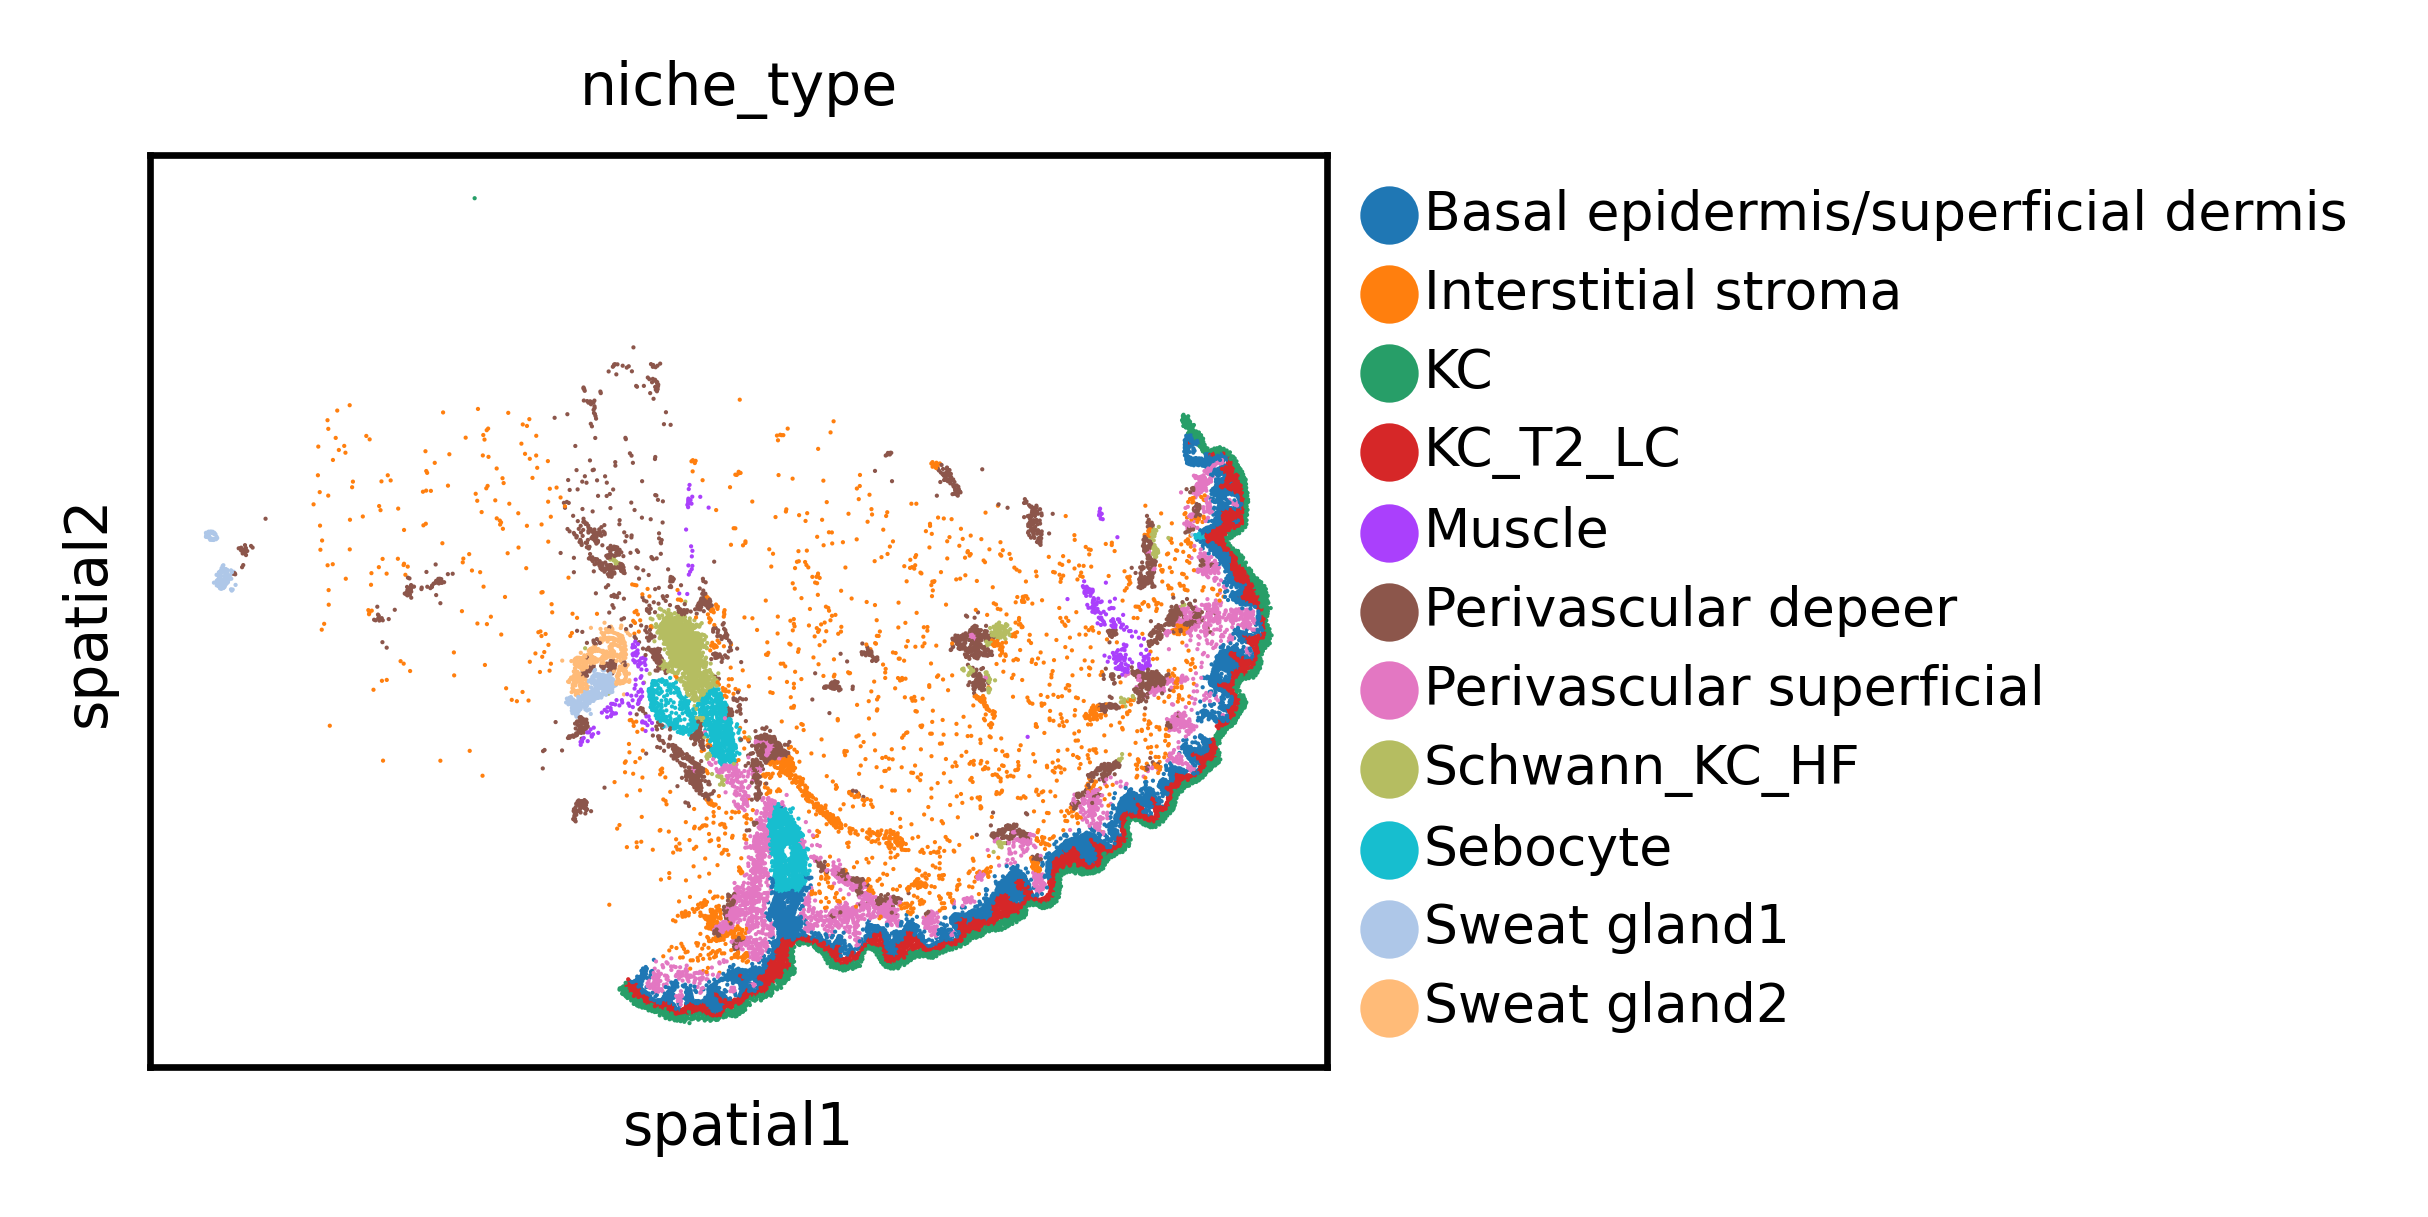

In [366]:
# Visualize data
sc.pl.spatial(adata,
              spot_size=spot_size,
              color=cell_type_key)

In [396]:
lr_database = 'omnipath'

In [397]:
# Retrieve ligand-receptor interaction pairs
if lr_database == 'omnipath': # 1159 pairs
    # Get OmniPath ligand-receptor interactions
    lr_interaction_df = get_adata_omnipath_lr_pairs(
        adata=adata,
        min_curation_effort=2)
elif lr_database == 'cellphonedb': # 414 pairs
    # Get CellPhoneDB ligand-receptor interactions
    lr_interaction_df = get_adata_cellphonedb_lr_pairs(
        adata=adata,
        save_folder_path=f'{artifacts_folder_path}/cellphonedb',
        cpdb_version='v5.0.0')


In [398]:
lr_interaction_df

,ligand,receptor
66,ENSG00000187266,ENSG00000138741
84,ENSG00000010810,ENSG00000133107
111,ENSG00000010810,ENSG00000137672
183,ENSG00000010810,ENSG00000111199
337,ENSG00000133116,ENSG00000165125
...,...,...
88693,ENSG00000113520,ENSG00000166888
89474,ENSG00000067182,ENSG00000065559
90565,ENSG00000019991,ENSG00000100030
90821,ENSG00000125538,ENSG00000105397


#### 2.1.2 Harmonize Data
If you’ve already tokenized your data, go to Load Tokenized Data and load the previously tokenized files.

In [370]:
adata = harmonize_adata(adata)

STEP 1: ADDING ENSEMBL IDS...
Adding ensembl IDs from release 110...


INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_m/mv10/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.cdna.all.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_m/mv10/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.ncrna.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_m/mv10/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.pep.all.fa.gz.pickle


Number of genes with matching ensembl IDs:           4948.
Number of genes skipped:           0.
STEP 2: ADDING SPECIAL VALUES...


/nfs/team361/mv10/.deep_speed_test/lib/python3.10/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


#### 2.1.3 Tokenize Data
If you’ve already tokenized your data, go to Load Tokenized Data and load the previously tokenized files.

In [371]:
dataset = tokenize_adata(adata,
                         model_folder_path,
                         nproc = 4,
                         processing_mode = 'parallel')

#item = dataset[0]
#print(item)

INFO:nichejepa.tokenizers.cell_tokenizers:Loading token dictionary from /nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/11062025_183320_055/token_dictionary.pkl.


STEP 1: LOADING CONFIG...
STEP 2: TOKENIZING ANNDATA OBJECT...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
Normalizing gene expression counts...
Retrieving gene tokens.


/nfs/team361/mv10/nemo_v6/nichejepa/src/nichejepa/tokenizers/cell_tokenizers.py:654: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  coding_miRNA_ids = adata.var['ensembl_id'][coding_miRNA_idx]


Ranking gene tokens based on normalized counts.
Retrieving tokens for neighborhood cells.


INFO:nichejepa.tokenizers.cell_tokenizers:Creating Hugging Face dataset...
INFO:nichejepa.tokenizers.cell_tokenizers:Using dictionary for dataset creation.
INFO:nichejepa.tokenizers.cell_tokenizers:Formatting gene tokens...


Map (num_proc=4):   0%|          | 0/18439 [00:00<?, ? examples/s]

#### 2.1.4 Save Tokenize Data

In [372]:
num_shards = 32
save_dataset_path = f"/lustre/scratch126/cellgen/lotfollahi/mv10/tokenized_data/{dataset_name}/{batch_name.split('.')[0]}"

In [304]:
!ls /lustre/scratch126/cellgen/lotfollahi/mv10/tokenized_data/xhs1000-39b_1p/

data-00000-of-00032.arrow  data-00012-of-00032.arrow  data-00024-of-00032.arrow
data-00001-of-00032.arrow  data-00013-of-00032.arrow  data-00025-of-00032.arrow
data-00002-of-00032.arrow  data-00014-of-00032.arrow  data-00026-of-00032.arrow
data-00003-of-00032.arrow  data-00015-of-00032.arrow  data-00027-of-00032.arrow
data-00004-of-00032.arrow  data-00016-of-00032.arrow  data-00028-of-00032.arrow
data-00005-of-00032.arrow  data-00017-of-00032.arrow  data-00029-of-00032.arrow
data-00006-of-00032.arrow  data-00018-of-00032.arrow  data-00030-of-00032.arrow
data-00007-of-00032.arrow  data-00019-of-00032.arrow  data-00031-of-00032.arrow
data-00008-of-00032.arrow  data-00020-of-00032.arrow  dataset_info.json
data-00009-of-00032.arrow  data-00021-of-00032.arrow  state.json
data-00010-of-00032.arrow  data-00022-of-00032.arrow
data-00011-of-00032.arrow  data-00023-of-00032.arrow


In [373]:
save_dataset_path

'/lustre/scratch126/cellgen/lotfollahi/mv10/tokenized_data/xhs1000-39b_1p/adata_batch32'

In [374]:
!mkdir save_dataset_path

mkdir: cannot create directory ‘save_dataset_path’: File exists


In [375]:
dataset.save_to_disk(
            save_dataset_path,
            num_shards=num_shards)

Saving the dataset (0/32 shards):   0%|          | 0/18439 [00:00<?, ? examples/s]

#### 2.1.5 Load Tokenize Data

In [22]:
load_dataset_path = f'/lustre/scratch126/cellgen/lotfollahi/mv10/tokenized_data/{dataset_name}/{batch_name}'
dataset = load_from_disk(load_dataset_path)

Loading dataset from disk:   0%|          | 0/32 [00:00<?, ?it/s]

In [376]:
dataset

Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_ids', 'cell_id', 'batch_token', 'gene_panel_token', 'assay_token', 'species_token', 'tissue_token', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'seg_tokens', 'n_nonzero_tokens'],
    num_rows: 18439
})

#### get summery of gene_experesion on this data

In [15]:
def summarize_gene_expression(
    adata,
    subset_cell_ids: list,
    top_n: int = 10,
    ensembl_col: str = "ensembl_id"
):
    """
    Filter AnnData to a subset of cells, compute gene expression summaries,
    and return top expressed genes with Ensembl IDs.

    Args:
        adata (AnnData): Pre-loaded AnnData object.
        subset_cell_ids (list): List of cell IDs to filter.
        top_n (int): Number of top expressed genes to return.
        ensembl_col (str): Column in adata.var that contains Ensembl IDs.

    Returns:
        combined_counts (pd.DataFrame): Filtered cell-by-gene count matrix.
        top_gene_df (pd.DataFrame): DataFrame with top gene names and Ensembl IDs.
    """
    if 'cell_id' not in adata.obs.columns:
        raise KeyError("Expected `adata.obs` to contain a 'cell_id' column.")
    if ensembl_col not in adata.var.columns:
        raise KeyError(f"Expected `adata.var` to contain '{ensembl_col}' column.")

    # Filter to subset of cells
    mask = adata.obs['cell_id'].astype(str).isin(set(subset_cell_ids))
    filtered = adata[mask].copy()
    if filtered.n_obs == 0:
        raise ValueError("No matching cells found in the provided subset.")

    # Extract dense matrix
    matrix = filtered.X.toarray() if hasattr(filtered.X, "toarray") else filtered.X
    combined_counts = pd.DataFrame(matrix, columns=filtered.var_names, index=filtered.obs_names)

    # Compute mean expression and get top N genes
    mean_expr = combined_counts.mean(axis=0)
    top_genes = mean_expr.nlargest(top_n)

    # Map to Ensembl IDs
    var_df = adata.var.loc[top_genes.index]
    top_gene_df = pd.DataFrame({
        "gene_name": top_genes.index,
        "ensembl_id": var_df[ensembl_col].values,
        "mean_expression": top_genes.values
    })

    return combined_counts, top_gene_df


In [16]:
combined_counts, top_gene_df = summarize_gene_expression(adata, list(adata.obs['cell_id']),top_n=1000)

#### 2.1.9 subset dataset instruction
You can use this method of subsetting dataasets in all your tasks. This is just a template for how to use it.

In [68]:
subset_cell_ids = ['1002_batch40_0',
 '1002_batch40_1',
 '1002_batch40_2',
 '1002_batch40_3',
 '1002_batch40_4',
 '1002_batch40_5',
 '1002_batch40_6',
 '1002_batch40_7',
 '1002_batch40_8',
 '1002_batch40_9']


In [75]:
dataset_subset = subset_by_cell_ids(dataset, subset_cell_ids)

Finding matching indices: 100%|█████████████████████████████████████████████| 321911/321911 [00:00<00:00, 5990020.70it/s]


In [78]:
dataset_subset

Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_ids', 'cell_id', 'batch_token', 'gene_panel_token', 'assay_token', 'species_token', 'tissue_token', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'seg_tokens', 'n_nonzero_tokens'],
    num_rows: 10
})

#### 2.1.10 get_gene_representation
Please note that the model was trained using Ensembl release 110, so for correct mapping you should use release 110 when looking up a gene’s Ensembl ID.

In [21]:
emb_layer = None
top_k = None
batch_size = 128
pin_memory = False
num_workers = 12

In [22]:
cell_gene_ensembl_id = ['ENSG00000104419', 'ENSG00000130402']
neighborhood_gene_ensembl_id = ['ENSG00000104419','ENSG00000130402'] # ['all'] * len(perturbed_cell_id)

In [ ]:
output_gene_embed = get_gene_embed( dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

In [37]:
for gene_ens in output_gene_embed.keys():
    adata.obsm[gene_ens] = output_gene_embed[gene_ens]

#### 2.1.11 get_average_gene_representation
Please note that the model was trained using Ensembl release 110, so for correct mapping you should use release 110 when looking up a gene’s Ensembl ID.

In [377]:
emb_layer = None
batch_size = 128
pin_memory = False
num_workers = 12
agg_excluded_tokens = None
top_k = None

In [378]:
lr_interaction_df

,ligand,receptor
2,ENSG00000039068,ENSG00000139187
4,ENSG00000170558,ENSG00000104921
232,ENSG00000090339,ENSG00000005844
237,ENSG00000108622,ENSG00000090659
239,ENSG00000076662,ENSG00000090659
...,...,...
2895,ENSG00000170893,ENSG00000174417
2900,ENSG00000204936,ENSG00000261371
2901,ENSG00000196776,ENSG00000198053
2902,ENSG00000196776,ENSG00000089012


In [399]:
cell_gene_ensembl_id = lr_interaction_df['receptor'].values.tolist()
neighborhood_gene_ensembl_id = list(adata.var['ensembl_id']) # ['all'] * len(perturbed_cell_id)

In [406]:
len(cell_gene_ensembl_id)

1159

In [401]:
emb_layer = None
batch_size = 128
pin_memory = False
num_workers = 12
agg_excluded_tokens = None
top_k = None

In [407]:
output_average_gene_embed = get_average_gene_embed(dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

STEP 1: LOADING CONFIG...
STEP 2: GETTING AVERAGE GENE EMBEDDINGS


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr', 'iter_number']


0it [00:00, ?it/s]/nfs/team361/mv10/nemo_v6/nichejepa/src/app/infer.py:1436: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
/usr/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
145it [42:19, 17.51s/it]
/nfs/team361/mv10/nemo_v6/nichejepa/src/app/infer.py:1694: RuntimeWarning: invalid value encountered in divide
  cell_gene_emb_features.append((sum_emb / count_emb).reshape(1, -1))
/nfs/team361/mv10/nemo_v6/nichejepa/src/app/infer.py:1701: RuntimeWarning: invalid value encountered in divide
  neighborhood_gene_emb_features.append((sum_emb / count_emb).reshape(1, -1))


In [576]:
#file_path = 'xhs1000-39b_1p_adata_batch11.h5ad_cellphonedb.json'
#file_path = 'xhs1000-39b_1p_adata_batch11.h5ad_omnipath.json'
#file_path = 'xhs1000-39b_1p_adata_batch19.h5ad_cellphonedb.json'
#file_path = 'xhs1000-39b_1p_adata_batch19.h5ad_omnipath.json'
file_path = 'xhs1000-39b_1p_adata_batch32.h5ad_cellphonedb.json'
#file_path = 'xhs1000-39b_1p_adata_batch32.h5ad_omnipath.json'
with open(file_path, 'rb') as f:
    output_average_gene_embed = pickle.load(f)


In [577]:
adata.uns['cell_gene_emb_average_per_data'] = output_average_gene_embed['cell_gene_emb_average_per_data']
adata.uns['cell_gene_emb_counts_per_data'] = output_average_gene_embed['cell_gene_emb_counts_per_data']
adata.uns['neighborhood_gene_emb_average_per_data'] = output_average_gene_embed['neighborhood_gene_emb_average_per_data']
adata.uns['neighborhood_gene_emb_counts_per_data'] = output_average_gene_embed['neighborhood_gene_emb_counts_per_data']

In [588]:
def compute_similarity(adata, cell_ids, nb_ids, min_count=20):
    """
    Compute filtered cosine‐similarity between cell and neighborhood embeddings.

    Parameters
    ----------
    adata : AnnData
        Must contain in `.uns` the keys:
          - 'cell_gene_emb_average_per_data'       : (n_cells, d)
          - 'cell_gene_emb_counts_per_data'        : (n_cells, 1) or (n_cells,)
          - 'neighborhood_gene_emb_average_per_data': (n_nb, d)
          - 'neighborhood_gene_emb_counts_per_data' : (n_nb, 1) or (n_nb,)
    cell_ids : sequence of str
        Ensembl IDs for the rows of the cell embeddings (length n_cells).
    nb_ids : sequence of str
        Ensembl IDs for the rows of the neighborhood embeddings (length n_nb).
    min_count : int
        Threshold below which rows are filtered out.

    Returns
    -------
    sim : np.ndarray, shape (n_cells_kept, n_nb_kept)
        Cosine‐similarities between each kept cell and kept neighborhood.
    kept_cell_idx : np.ndarray, shape (n_cells_kept,)
        Indices of the original cell rows that passed the filter.
    kept_nb_idx : np.ndarray, shape (n_nb_kept,)
        Indices of the original neighborhood rows that passed the filter.
    """
    # 1. Load embeddings & counts
    cell_avg = adata.uns['cell_gene_emb_average_per_data']
    cell_cnt = np.array(adata.uns['cell_gene_emb_counts_per_data']).squeeze()
    nb_avg   = adata.uns['neighborhood_gene_emb_average_per_data']
    nb_cnt   = np.array(adata.uns['neighborhood_gene_emb_counts_per_data']).squeeze()

    # 2. Independent filter by count
    keep_cells = cell_cnt >= min_count
    keep_nbs   = nb_cnt   >= min_count
    kept_cell_idx = np.where(keep_cells)[0]
    kept_nb_idx   = np.where(keep_nbs)[0]

    cell_f = cell_avg[keep_cells]
    nb_f   = nb_avg[keep_nbs]

    # 3. Compute cosine similarity
    sim = cosine_similarity(cell_f, nb_f)

    return sim, kept_cell_idx, kept_nb_idx


In [512]:
#with open(f'{dataset_name}_{batch_name}_{lr_database}.json', 'wb') as f:
#    pickle.dump(output_average_gene_embed, f)

In [585]:
def top_k(sim_row, k):
    """
    Given a 1D array of similarities, return the top-k indices (in descending order)
    and their corresponding similarity scores.
    """
    order   = np.argsort(sim_row)[::-1]
    top_ids = order[:k]
    return top_ids, sim_row[top_ids]


def assemble_enriched_results(
    sim,
    cell_idx,
    nb_idx,
    cell_ids,
    nb_ids,
    ensembl2gene,
    top_n=5
):
    """
    Build enriched_results:
      { cell_ensembl: { 'cell_gene_name': str,
                        'top_neighbors': [
                          {'neigh_ensembl_id': str,
                           'neigh_gene_name': str,
                           'cosine_score': float},
                          … ] } }

    Parameters
    ----------
    sim : np.ndarray, shape (n_cells_kept, n_nb_kept)
        Cosine‐similarity matrix.
    cell_idx : array‐like of int
        Indices of the kept cells (mapping rows of `sim` back to original).
    nb_idx : array‐like of int
        Indices of the kept neighborhoods (mapping cols of `sim` back to original).
    cell_ids : list[str]
        Full original Ensembl IDs for cells.
    nb_ids : list[str]
        Full original Ensembl IDs for neighborhoods.
    ensembl2gene : dict
        Mapping from Ensembl ID → gene_name.
    top_n : int
        How many neighbors to return per cell.

    Returns
    -------
    enriched_results : dict
    """
    enriched_results = {}

    for i, sim_row in enumerate(sim):
        # map back to original cell
        cell_orig     = cell_idx[i]
        cell_ens      = cell_ids[cell_orig]
        cell_name     = ensembl2gene.get(cell_ens, cell_ens)

        # pick top_n neighborhoods
        neigh_pos, scores = top_k(sim_row, top_n)
        hits = []
        for pos, score in zip(neigh_pos, scores):
            neigh_orig   = nb_idx[pos]
            neigh_ens    = nb_ids[neigh_orig]
            neigh_name   = ensembl2gene.get(neigh_ens, neigh_ens)
            hits.append({
                'neigh_ensembl_id': neigh_ens,
                'neigh_gene_name':  neigh_name,
                'cosine_score':     float(score)
            })

        enriched_results[cell_ens] = {
            'cell_gene_name': cell_name,
            'top_neighbors':  hits
        }

    return enriched_results


In [586]:
def enriched_results_to_df(enriched_results):
    """
    Convert enriched_results dict into a single pandas DataFrame.

    Parameters
    ----------
    enriched_results : dict
        {
          cell_ensembl_id: {
            'cell_gene_name': str,
            'top_neighbors': [
               {'neigh_ensembl_id': str,
                'neigh_gene_name':  str,
                'cosine_score':     float},
               …
            ]
          },
          …
        }

    Returns
    -------
    df : pandas.DataFrame
        Columns: ['cell_ensembl_id','cell_gene_name',
                  'neigh_ensembl_id','neigh_gene_name','cosine_similarity']
    """
    rows = []
    for cell_ens, info in enriched_results.items():
        for hit in info['top_neighbors']:
            rows.append({
                'cell_ensembl_id':   cell_ens,
                'cell_gene_name':    info['cell_gene_name'],
                'neigh_ensembl_id':  hit['neigh_ensembl_id'],
                'neigh_gene_name':   hit['neigh_gene_name'],
                'cosine_similarity': hit['cosine_score'],
            })
    return pd.DataFrame(rows)


In [587]:
def rank_and_merge_lr_interactions(
    df: pd.DataFrame,
    lr_interaction_df: pd.DataFrame,
    ensembl2gene: dict
) -> pd.DataFrame:
    """
    For each receptor–ligand pair in `lr_interaction_df`, find its rank and score
    from `df`, and add gene names.

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame with columns:
          - 'cell_ensembl_id'
          - 'cell_gene_name'
          - 'neigh_ensembl_id'
          - 'neigh_gene_name'
          - 'cosine_similarity'
        Here 'cell_ensembl_id' acts as receptor and 'neigh_ensembl_id' as ligand.
    lr_interaction_df : pd.DataFrame
        DataFrame with columns ['ligand','receptor'] of Ensembl IDs.
    ensembl2gene : dict
        Mapping from Ensembl ID to gene_name.

    Returns
    -------
    final_df : pd.DataFrame
        Columns:
          - ligand (Ensembl ID)
          - ligand_gene_name
          - receptor (Ensembl ID)
          - receptor_gene_name
          - rank (int)
          - score (float)
    """
    # 1. Rank each receptor’s ligands by similarity
    df_ranked = df.copy()
    df_ranked['rank'] = (
        df_ranked
        .groupby('cell_ensembl_id')['cosine_similarity']
        .rank(method='first', ascending=False)
        .astype(int)
    )

    # 2. Merge ligand–receptor info with rankings & scores
    merged = lr_interaction_df.merge(
        df_ranked[[
            'cell_ensembl_id', 'cell_gene_name',
            'neigh_ensembl_id', 'neigh_gene_name',
            'cosine_similarity', 'rank'
        ]],
        left_on=['receptor', 'ligand'],
        right_on=['cell_ensembl_id', 'neigh_ensembl_id'],
        how='left'
    )

    # 3. Fill missing gene names from ensembl2gene
    for col, ens_col in [('cell_gene_name','receptor'), ('neigh_gene_name','ligand')]:
        merged[col] = merged[col].fillna(merged[ens_col].map(ensembl2gene))

    # 4. Select & rename
    final_df = (
        merged
        .rename(columns={
           'cosine_similarity':      'score',
           'cell_gene_name':         'receptor_gene_name',
           'neigh_gene_name':        'ligand_gene_name'
        })
        [['ligand','ligand_gene_name',
          'receptor','receptor_gene_name',
          'rank','score']]
    )
    return final_df


In [612]:
file_path = 'xhs1000-39b_1p_adata_batch32.h5ad_omnipath.json'
with open(file_path, 'rb') as f:
    output_average_gene_embed = pickle.load(f)

adata.uns['cell_gene_emb_average_per_data'] = output_average_gene_embed['cell_gene_emb_average_per_data']
adata.uns['cell_gene_emb_counts_per_data'] = output_average_gene_embed['cell_gene_emb_counts_per_data']
adata.uns['neighborhood_gene_emb_average_per_data'] = output_average_gene_embed['neighborhood_gene_emb_average_per_data']
adata.uns['neighborhood_gene_emb_counts_per_data'] = output_average_gene_embed['neighborhood_gene_emb_counts_per_data']
# 1) Compute filtered cosine similarities
sim, cell_idx, nb_idx = compute_similarity(
    adata,
    cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id,
    min_count=20
)
# 2) Build Ensembl→gene_name map
var = adata.var.reset_index()  # columns ['gene_name','ensembl_id',...]
ensembl2gene = dict(zip(var['ensembl_id'], var['gene_name']))

# 3) Assemble enriched_results (top‐k neighbors per cell)
enriched = assemble_enriched_results(
    sim,
    cell_idx,
    nb_idx,
    cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id,
    ensembl2gene,
    top_n=5000
)

# 4) Flatten enriched_results into a DataFrame
df = enriched_results_to_df(enriched)

# 5) Rank & merge with your ligand–receptor list
final_df = rank_and_merge_lr_interactions(
    df,
    lr_interaction_df,
    ensembl2gene
)

# `final_df` now has columns:
#   ligand, ligand_gene_name,
#   receptor, receptor_gene_name,
#   rank, score


In [613]:
final_df.sort_values(by='rank').dropna()

,ligand,ligand_gene_name,receptor,receptor_gene_name,rank,score
45,ENSG00000141510,TP53,ENSG00000104689,TNFRSF10A,3.0,0.597230
1077,ENSG00000128052,KDR,ENSG00000037280,FLT4,7.0,0.692086
200,ENSG00000128917,DLL4,ENSG00000204301,NOTCH4,11.0,0.673839
936,ENSG00000154188,ANGPT1,ENSG00000161638,ITGA5,14.0,0.430933
139,ENSG00000153563,CD8A,ENSG00000182866,LCK,17.0,0.670436
...,...,...,...,...,...,...
1138,ENSG00000037280,FLT4,ENSG00000065559,MAP2K4,4584.0,0.112645
562,ENSG00000181092,ADIPOQ,ENSG00000006831,ADIPOR2,4588.0,0.131913
905,ENSG00000185559,DLK1,ENSG00000074181,NOTCH3,4610.0,0.088750
993,ENSG00000185559,DLK1,ENSG00000204301,NOTCH4,4614.0,0.045588


In [624]:
file_path = 'xhs1000-39b_1p_adata_batch19.h5ad_omnipath.json'
with open(file_path, 'rb') as f:
    output_average_gene_embed = pickle.load(f)

adata.uns['cell_gene_emb_average_per_data'] = output_average_gene_embed['cell_gene_emb_average_per_data']
adata.uns['cell_gene_emb_counts_per_data'] = output_average_gene_embed['cell_gene_emb_counts_per_data']
adata.uns['neighborhood_gene_emb_average_per_data'] = output_average_gene_embed['neighborhood_gene_emb_average_per_data']
adata.uns['neighborhood_gene_emb_counts_per_data'] = output_average_gene_embed['neighborhood_gene_emb_counts_per_data']
# 1) Compute filtered cosine similarities
sim, cell_idx, nb_idx = compute_similarity(
    adata,
    cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id,
    min_count=20
)
# 2) Build Ensembl→gene_name map
var = adata.var.reset_index()  # columns ['gene_name','ensembl_id',...]
ensembl2gene = dict(zip(var['ensembl_id'], var['gene_name']))

# 3) Assemble enriched_results (top‐k neighbors per cell)
enriched = assemble_enriched_results(
    sim,
    cell_idx,
    nb_idx,
    cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id,
    ensembl2gene,
    top_n=5000
)

# 4) Flatten enriched_results into a DataFrame
df = enriched_results_to_df(enriched)

# 5) Rank & merge with your ligand–receptor list
final_df = rank_and_merge_lr_interactions(
    df,
    lr_interaction_df,
    ensembl2gene
)

# `final_df` now has columns:
#   ligand, ligand_gene_name,
#   receptor, receptor_gene_name,
#   rank, score


In [629]:
df[df['cell_ensembl_id']=='ENSG00000213658']

,cell_ensembl_id,cell_gene_name,neigh_ensembl_id,neigh_gene_name,cosine_similarity
522480,ENSG00000213658,LAT,ENSG00000213658,LAT,0.910928
522481,ENSG00000213658,LAT,ENSG00000110031,LPXN,0.567103
522482,ENSG00000213658,LAT,ENSG00000168421,RHOH,0.549694
522483,ENSG00000213658,LAT,ENSG00000035720,STAP1,0.535572
522484,ENSG00000213658,LAT,ENSG00000010810,FYN,0.528909
...,...,...,...,...,...
527140,ENSG00000213658,LAT,ENSG00000081181,ARG2,0.051883
527141,ENSG00000213658,LAT,ENSG00000145879,SPINK7,0.042984
527142,ENSG00000213658,LAT,ENSG00000136697,IL1F10,0.027790
527143,ENSG00000213658,LAT,ENSG00000084674,APOB,0.010070


In [631]:
final_df.sort_values(by='rank').dropna().head(30)

,ligand,ligand_gene_name,receptor,receptor_gene_name,rank,score
45,ENSG00000141510,TP53,ENSG00000104689,TNFRSF10A,2.0,0.606693
936,ENSG00000154188,ANGPT1,ENSG00000161638,ITGA5,5.0,0.475534
579,ENSG00000010810,FYN,ENSG00000213658,LAT,5.0,0.528909
1077,ENSG00000128052,KDR,ENSG00000037280,FLT4,5.0,0.685476
673,ENSG00000138685,FGF2,ENSG00000169439,SDC2,7.0,0.524800
200,ENSG00000128917,DLL4,ENSG00000204301,NOTCH4,12.0,0.659831
258,ENSG00000091879,ANGPT2,ENSG00000120156,TEK,14.0,0.561632
139,ENSG00000153563,CD8A,ENSG00000182866,LCK,15.0,0.698067
189,ENSG00000077238,IL4R,ENSG00000166888,STAT6,16.0,0.538696
826,ENSG00000091879,ANGPT2,ENSG00000066056,TIE1,17.0,0.587810


In [616]:
file_path = 'xhs1000-39b_1p_adata_batch11.h5ad_omnipath.json'
with open(file_path, 'rb') as f:
    output_average_gene_embed = pickle.load(f)

adata.uns['cell_gene_emb_average_per_data'] = output_average_gene_embed['cell_gene_emb_average_per_data']
adata.uns['cell_gene_emb_counts_per_data'] = output_average_gene_embed['cell_gene_emb_counts_per_data']
adata.uns['neighborhood_gene_emb_average_per_data'] = output_average_gene_embed['neighborhood_gene_emb_average_per_data']
adata.uns['neighborhood_gene_emb_counts_per_data'] = output_average_gene_embed['neighborhood_gene_emb_counts_per_data']
# 1) Compute filtered cosine similarities
sim, cell_idx, nb_idx = compute_similarity(
    adata,
    cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id,
    min_count=20
)
# 2) Build Ensembl→gene_name map
var = adata.var.reset_index()  # columns ['gene_name','ensembl_id',...]
ensembl2gene = dict(zip(var['ensembl_id'], var['gene_name']))

# 3) Assemble enriched_results (top‐k neighbors per cell)
enriched = assemble_enriched_results(
    sim,
    cell_idx,
    nb_idx,
    cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id,
    ensembl2gene,
    top_n=5000
)

# 4) Flatten enriched_results into a DataFrame
df = enriched_results_to_df(enriched)

# 5) Rank & merge with your ligand–receptor list
final_df = rank_and_merge_lr_interactions(
    df,
    lr_interaction_df,
    ensembl2gene
)

# `final_df` now has columns:
#   ligand, ligand_gene_name,
#   receptor, receptor_gene_name,
#   rank, score


In [617]:
final_df.sort_values(by='rank').dropna()

,ligand,ligand_gene_name,receptor,receptor_gene_name,rank,score
45,ENSG00000141510,TP53,ENSG00000104689,TNFRSF10A,2.0,0.616599
673,ENSG00000138685,FGF2,ENSG00000169439,SDC2,5.0,0.514750
1077,ENSG00000128052,KDR,ENSG00000037280,FLT4,7.0,0.695871
200,ENSG00000128917,DLL4,ENSG00000204301,NOTCH4,9.0,0.694560
940,ENSG00000275385,CCL18,ENSG00000163823,CCR1,11.0,0.517440
...,...,...,...,...,...,...
1082,ENSG00000261371,PECAM1,ENSG00000197122,SRC,4730.0,0.183842
533,ENSG00000181092,ADIPOQ,ENSG00000159346,ADIPOR1,4736.0,0.115382
470,ENSG00000234829,IFNA17,ENSG00000142166,IFNAR1,4737.0,0.113790
691,ENSG00000136697,IL1F10,ENSG00000185187,SIGIRR,4738.0,0.134473


In [618]:
file_path = 'xhs1000-39b_1p_adata_batch32.h5ad_cellphonedb.json'
with open(file_path, 'rb') as f:
    output_average_gene_embed = pickle.load(f)

adata.uns['cell_gene_emb_average_per_data'] = output_average_gene_embed['cell_gene_emb_average_per_data']
adata.uns['cell_gene_emb_counts_per_data'] = output_average_gene_embed['cell_gene_emb_counts_per_data']
adata.uns['neighborhood_gene_emb_average_per_data'] = output_average_gene_embed['neighborhood_gene_emb_average_per_data']
adata.uns['neighborhood_gene_emb_counts_per_data'] = output_average_gene_embed['neighborhood_gene_emb_counts_per_data']
# 1) Compute filtered cosine similarities
sim, cell_idx, nb_idx = compute_similarity(
    adata,
    cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id,
    min_count=20
)
# 2) Build Ensembl→gene_name map
var = adata.var.reset_index()  # columns ['gene_name','ensembl_id',...]
ensembl2gene = dict(zip(var['ensembl_id'], var['gene_name']))

# 3) Assemble enriched_results (top‐k neighbors per cell)
enriched = assemble_enriched_results(
    sim,
    cell_idx,
    nb_idx,
    cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id,
    ensembl2gene,
    top_n=5000
)

# 4) Flatten enriched_results into a DataFrame
df = enriched_results_to_df(enriched)

# 5) Rank & merge with your ligand–receptor list
final_df = rank_and_merge_lr_interactions(
    df,
    lr_interaction_df,
    ensembl2gene
)

# `final_df` now has columns:
#   ligand, ligand_gene_name,
#   receptor, receptor_gene_name,
#   rank, score


In [619]:
final_df.sort_values(by='rank').dropna()

,ligand,ligand_gene_name,receptor,receptor_gene_name,rank,score
1144,ENSG00000148400,NOTCH1,ENSG00000204301,NOTCH4,2.0,0.561578
61,ENSG00000102245,CD40LG,ENSG00000101017,CD40,5.0,0.719227
663,ENSG00000128917,DLL4,ENSG00000074181,NOTCH3,11.0,0.673839
116,ENSG00000141510,TP53,ENSG00000087586,AURKA,61.0,0.521315
40,ENSG00000141510,TP53,ENSG00000105976,MET,61.0,0.521315
...,...,...,...,...,...,...
289,ENSG00000119535,CSF3R,ENSG00000096968,JAK2,4608.0,0.105983
284,ENSG00000138798,EGF,ENSG00000141736,ERBB2,4609.0,0.095349
993,ENSG00000185559,DLK1,ENSG00000204301,NOTCH4,4610.0,0.088750
905,ENSG00000185559,DLK1,ENSG00000074181,NOTCH3,4614.0,0.045588


In [620]:
file_path = 'xhs1000-39b_1p_adata_batch19.h5ad_cellphonedb.json'
with open(file_path, 'rb') as f:
    output_average_gene_embed = pickle.load(f)

adata.uns['cell_gene_emb_average_per_data'] = output_average_gene_embed['cell_gene_emb_average_per_data']
adata.uns['cell_gene_emb_counts_per_data'] = output_average_gene_embed['cell_gene_emb_counts_per_data']
adata.uns['neighborhood_gene_emb_average_per_data'] = output_average_gene_embed['neighborhood_gene_emb_average_per_data']
adata.uns['neighborhood_gene_emb_counts_per_data'] = output_average_gene_embed['neighborhood_gene_emb_counts_per_data']
# 1) Compute filtered cosine similarities
sim, cell_idx, nb_idx = compute_similarity(
    adata,
    cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id,
    min_count=20
)
# 2) Build Ensembl→gene_name map
var = adata.var.reset_index()  # columns ['gene_name','ensembl_id',...]
ensembl2gene = dict(zip(var['ensembl_id'], var['gene_name']))

# 3) Assemble enriched_results (top‐k neighbors per cell)
enriched = assemble_enriched_results(
    sim,
    cell_idx,
    nb_idx,
    cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id,
    ensembl2gene,
    top_n=5000
)

# 4) Flatten enriched_results into a DataFrame
df = enriched_results_to_df(enriched)

# 5) Rank & merge with your ligand–receptor list
final_df = rank_and_merge_lr_interactions(
    df,
    lr_interaction_df,
    ensembl2gene
)

# `final_df` now has columns:
#   ligand, ligand_gene_name,
#   receptor, receptor_gene_name,
#   rank, score


In [621]:
final_df.sort_values(by='rank').dropna()

,ligand,ligand_gene_name,receptor,receptor_gene_name,rank,score
1144,ENSG00000148400,NOTCH1,ENSG00000204301,NOTCH4,2.0,0.552660
61,ENSG00000102245,CD40LG,ENSG00000101017,CD40,5.0,0.731986
663,ENSG00000128917,DLL4,ENSG00000074181,NOTCH3,12.0,0.659831
277,ENSG00000112964,GHR,ENSG00000105397,TYK2,27.0,0.510223
238,ENSG00000113594,LIFR,ENSG00000134352,IL6ST,27.0,0.478618
...,...,...,...,...,...,...
601,ENSG00000118523,CCN2,ENSG00000070018,LRP6,4635.0,0.121414
306,ENSG00000136688,IL36G,ENSG00000159110,IFNAR2,4646.0,0.142383
853,ENSG00000136697,IL1F10,ENSG00000115594,IL1R1,4650.0,0.171054
289,ENSG00000119535,CSF3R,ENSG00000096968,JAK2,4656.0,0.138668


In [622]:
file_path = 'xhs1000-39b_1p_adata_batch11.h5ad_cellphonedb.json'
with open(file_path, 'rb') as f:
    output_average_gene_embed = pickle.load(f)

adata.uns['cell_gene_emb_average_per_data'] = output_average_gene_embed['cell_gene_emb_average_per_data']
adata.uns['cell_gene_emb_counts_per_data'] = output_average_gene_embed['cell_gene_emb_counts_per_data']
adata.uns['neighborhood_gene_emb_average_per_data'] = output_average_gene_embed['neighborhood_gene_emb_average_per_data']
adata.uns['neighborhood_gene_emb_counts_per_data'] = output_average_gene_embed['neighborhood_gene_emb_counts_per_data']
# 1) Compute filtered cosine similarities
sim, cell_idx, nb_idx = compute_similarity(
    adata,
    cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id,
    min_count=20
)
# 2) Build Ensembl→gene_name map
var = adata.var.reset_index()  # columns ['gene_name','ensembl_id',...]
ensembl2gene = dict(zip(var['ensembl_id'], var['gene_name']))

# 3) Assemble enriched_results (top‐k neighbors per cell)
enriched = assemble_enriched_results(
    sim,
    cell_idx,
    nb_idx,
    cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id,
    ensembl2gene,
    top_n=5000
)

# 4) Flatten enriched_results into a DataFrame
df = enriched_results_to_df(enriched)

# 5) Rank & merge with your ligand–receptor list
final_df = rank_and_merge_lr_interactions(
    df,
    lr_interaction_df,
    ensembl2gene
)

# `final_df` now has columns:
#   ligand, ligand_gene_name,
#   receptor, receptor_gene_name,
#   rank, score


In [623]:
final_df.sort_values(by='rank').dropna()

,ligand,ligand_gene_name,receptor,receptor_gene_name,rank,score
1144,ENSG00000148400,NOTCH1,ENSG00000204301,NOTCH4,2.0,0.559211
61,ENSG00000102245,CD40LG,ENSG00000101017,CD40,4.0,0.738799
663,ENSG00000128917,DLL4,ENSG00000074181,NOTCH3,9.0,0.694560
354,ENSG00000276409,CCL14,ENSG00000163823,CCR1,58.0,0.431203
40,ENSG00000141510,TP53,ENSG00000105976,MET,68.0,0.518102
...,...,...,...,...,...,...
858,ENSG00000185652,NTF3,ENSG00000198400,NTRK1,4726.0,0.061869
601,ENSG00000118523,CCN2,ENSG00000070018,LRP6,4728.0,0.066561
289,ENSG00000119535,CSF3R,ENSG00000096968,JAK2,4728.0,0.149914
284,ENSG00000138798,EGF,ENSG00000141736,ERBB2,4736.0,0.063364
